In [1]:
import pandas as pd

from geography import Geography

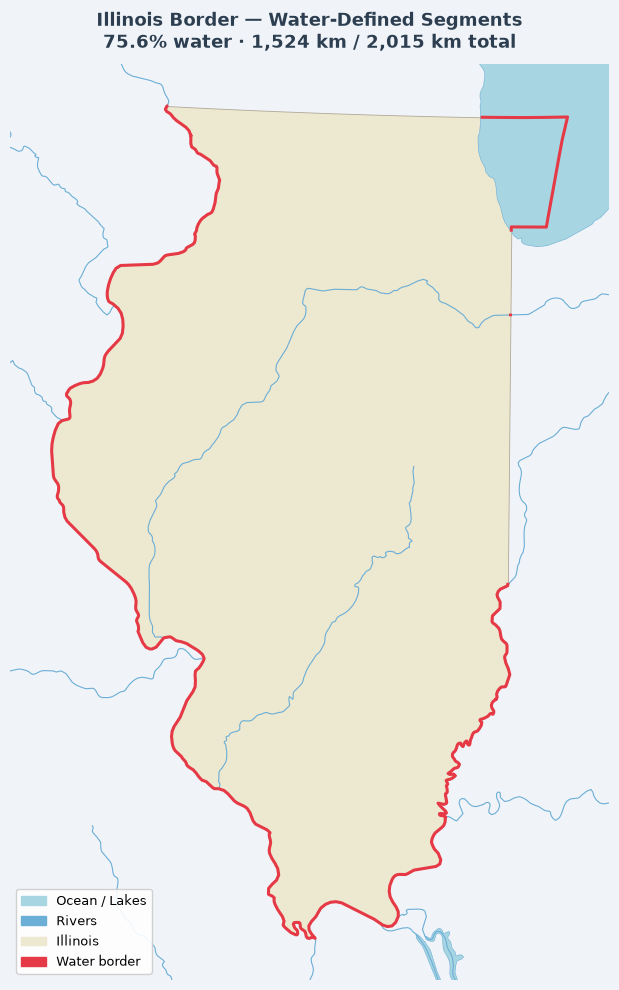

In [5]:
state = 'Illinois'

geog = Geography()
dict = geog.calculateWaterStateOverlap(state, 1000)
geog.plot(state, dict)

In [3]:
from config import STATE_CRS

bufferSize = 1000  # meters each side of a river centerline

records = []
for state_name in STATE_CRS:
    try:
        overlap = geog.calculateWaterStateOverlap(state_name, bufferSize)
        records.append({
            "state":     state_name,
            "crs":       STATE_CRS[state_name],
            "total_km":  round(overlap["stateLength"] / 1000, 1),
            "water_km":  round(overlap["waterLength"] / 1000, 1),
            "water_pct": round(overlap["percentOverlap"], 1),
        })
        # print(f"  {state_name:<20} {overlap['percentOverlap']:5.1f}%")
    except Exception as e:
        print(f"  {state_name:<20} ERROR: {e}")

all_states_df = (
    pd.DataFrame(records)
    .sort_values("water_pct", ascending=False)
    .reset_index(drop=True)
)
all_states_df

,state,crs,total_km,water_km,water_pct
0,Hawaii,EPSG:26904,1455.4,1455.4,100.0
1,Alaska,EPSG:3338,39612.0,37427.1,94.5
2,New Jersey,EPSG:26918,1069.2,992.5,92.8
3,Florida,EPSG:26917,5575.3,4868.2,87.3
4,Louisiana,EPSG:26915,3603.6,3045.3,84.5
5,Washington,EPSG:26910,3914.3,3053.6,78.0
6,Texas,EPSG:3083,6547.5,5063.2,77.3
7,Illinois,EPSG:26916,2014.8,1523.9,75.6
8,Michigan,EPSG:3078,2556.0,1920.0,75.1
9,Maryland,EPSG:26918,2788.2,2037.6,73.1
